In [1]:
import os
import glob
import numpy as np
import pandas as pd

TEST_PATH = "/kaggle/input/datasets/krrishshandilya/dipcoma-test/test"

MODEL_PATH = "/kaggle/input/notebooks/arvindreddy99920/pca-model/pca_results/pca_model.npz"

OUTPUT_PATH = "/kaggle/working/test_results"

os.makedirs(OUTPUT_PATH, exist_ok=True)

model = np.load(MODEL_PATH)

mean = model["mean"]
components = model["components"]
LO = model["LO"]
HI = model["HI"]

K = 8

print("Test notebook initialized successfully")
print("Test regions:", len(os.listdir(TEST_PATH)))
print("PCA components:", K)
print("Output directory:", OUTPUT_PATH)

Test notebook initialized successfully
Test regions: 6
PCA components: 8
Output directory: /kaggle/working/test_results


In [2]:
import os
import glob
import numpy as np
import pandas as pd
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

results = []

for region in sorted(os.listdir(TEST_PATH)):

    files = glob.glob(os.path.join(TEST_PATH, region, "*.npy"))

    for file in files:

        # Load and normalize original patch
        original = np.load(file).astype(np.float32)

        original = np.clip(original, LO[:, None, None], HI[:, None, None])
        original = (
            original - LO[:, None, None]
        ) / (HI[:, None, None] - LO[:, None, None])

        # Convert to (pixels, bands)
        X = original.reshape(13, -1).T

        # PCA compression and reconstruction
        scores = (X - mean) @ components[:K].T
        reconstructed = scores @ components[:K] + mean

        reconstructed = reconstructed.T.reshape(13, 512, 512)
        reconstructed = np.clip(reconstructed, 0, 1)

        # Quality metrics
        psnr_values = []
        ssim_values = []

        for band in range(13):
            psnr_values.append(
                peak_signal_noise_ratio(
                    original[band],
                    reconstructed[band],
                    data_range=1.0
                )
            )

            ssim_values.append(
                structural_similarity(
                    original[band],
                    reconstructed[band],
                    data_range=1.0
                )
            )

        # Spectral metrics
        original_pixels = X
        reconstructed_pixels = reconstructed.reshape(13, -1).T

        dot = np.sum(original_pixels * reconstructed_pixels, axis=1)

        norms = (
            np.linalg.norm(original_pixels, axis=1) *
            np.linalg.norm(reconstructed_pixels, axis=1)
        )

        cosine = np.divide(
            dot, norms,
            out=np.ones_like(dot),
            where=norms != 0
        )

        sam = np.degrees(
            np.arccos(np.clip(cosine, -1, 1))
        ).mean()

        mae = np.mean(np.abs(original_pixels - reconstructed_pixels))

        mre = np.mean(
            np.abs(original_pixels - reconstructed_pixels) /
            np.maximum(np.abs(original_pixels), 1e-8)
        )

        results.append({
            "region": region,
            "patch": os.path.basename(file),
            "PSNR": np.mean(psnr_values),
            "SSIM": np.mean(ssim_values),
            "SAM": sam,
            "MAE": mae,
            "MRE": mre
        })

    print(f"Completed: {region}")

pca_test = pd.DataFrame(results)

pca_test.to_csv(
    f"{OUTPUT_PATH}/standard_pca_test_results.csv",
    index=False
)

print("\nSTANDARD PCA TEST EVALUATION")
print("=" * 50)
print("Total patches:", len(pca_test))
print(pca_test[["PSNR", "SSIM", "SAM", "MAE", "MRE"]].mean())
print("\nResults saved successfully.")

Completed: everest_region
Completed: great_barrier_reef
Completed: lagos
Completed: northern_sweden
Completed: po_valley
Completed: rub_al_khali

STANDARD PCA TEST EVALUATION
Total patches: 396
PSNR     50.639685
SSIM      0.993306
SAM       1.705216
MAE       0.003820
MRE     460.255951
dtype: float64

Results saved successfully.


In [3]:

import os
import glob
import io
import time
import tracemalloc
import numpy as np
import pandas as pd

from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

# ============================================================
# 1. SETTINGS
# ============================================================

K = 8
TEST_PATH = "/kaggle/input/datasets/krrishshandilya/dipcoma-test/test"
OUTPUT_PATH = "/kaggle/working/test_results"

os.makedirs(OUTPUT_PATH, exist_ok=True)

band_count = 13
height = 512
width = 512

band_names = [
    "B01", "B02", "B03", "B04", "B05",
    "B06", "B07", "B08", "B8A", "B09",
    "B10", "B11", "B12"
]

patch_files = sorted(
    glob.glob(os.path.join(TEST_PATH, "**", "*.npy"), recursive=True)
)

print("TEST EVALUATION")
print("=" * 65)
print("Test patches:", len(patch_files))
print("Regions:", len(os.listdir(TEST_PATH)))
print("PCA components:", K)


# ============================================================
# 2. LOAD SAVED PCA MODEL
# ============================================================

model = np.load(MODEL_PATH)

mean = model["mean"].astype(np.float32)
components = model["components"].astype(np.float32)
LO = model["LO"].astype(np.float32)
HI = model["HI"].astype(np.float32)

selected = components[:K]

# Shared PCA model parameter count:
# mean vector + selected component matrix
pca_model_parameters = mean.size + selected.size

print("PCA model loaded.")
print("PCA model parameters:", pca_model_parameters)


# ============================================================
# 3. REDUNDANCY FUNCTION
# ============================================================

def calculate_redundancy(original):
    pixels = original.reshape(13, -1)
    correlation = np.corrcoef(pixels)

    upper = correlation[np.triu_indices(13, k=1)]
    upper = upper[np.isfinite(upper)]

    return np.mean(np.abs(upper))


# ============================================================
# 4. EVALUATION FUNCTION
# ============================================================

def evaluate_reconstruction(original, reconstructed):

    reconstructed = np.clip(reconstructed, 0, 1)

    original_pixels = original.reshape(13, -1).T
    reconstructed_pixels = reconstructed.reshape(13, -1).T

    # PSNR and SSIM
    psnr = peak_signal_noise_ratio(
        original, reconstructed, data_range=1.0
    )

    ssim = np.mean([
        structural_similarity(
            original[b],
            reconstructed[b],
            data_range=1.0
        )
        for b in range(13)
    ])

    # SAM
    dot = np.sum(original_pixels * reconstructed_pixels, axis=1)

    norms = (
        np.linalg.norm(original_pixels, axis=1) *
        np.linalg.norm(reconstructed_pixels, axis=1)
    )

    cosine = np.divide(
        dot,
        norms,
        out=np.ones_like(dot),
        where=norms != 0
    )

    sam = np.degrees(
        np.arccos(np.clip(cosine, -1, 1))
    ).mean()

    # MAE
    absolute_error = np.abs(
        original_pixels - reconstructed_pixels
    )

    mae = absolute_error.mean()

    # MRE: denominator floor avoids extreme values near zero
    mre = np.mean(
        absolute_error /
        np.maximum(np.abs(original_pixels), 1e-3)
    ) * 100

    return psnr, ssim, sam, mae, mre


# ============================================================
# 5. EVALUATE BOTH PCA METHODS
# ============================================================

results = []

for idx, path in enumerate(patch_files):

    region = os.path.basename(os.path.dirname(path))
    patch_name = os.path.basename(path)

    raw = np.load(path).astype(np.float32)

    original = np.clip(
        raw,
        LO[:, None, None],
        HI[:, None, None]
    )

    original = (
        original - LO[:, None, None]
    ) / (
        HI - LO
    )[:, None, None]

    X = original.reshape(13, -1).T
    centered = X - mean

    redundancy = calculate_redundancy(original)
    original_bytes = os.path.getsize(path)

    # Start memory tracking for this patch
    tracemalloc.start()

    # --------------------------------------------------------
    # STANDARD PCA ENCODING
    # --------------------------------------------------------

    start = time.perf_counter()

    scores = centered @ selected.T

    standard_buffer = io.BytesIO()

    np.savez_compressed(
        standard_buffer,
        scores=scores.astype(np.float32)
    )

    standard_bytes = len(standard_buffer.getvalue())

    standard_enc = time.perf_counter() - start

    # STANDARD PCA DECODING
    start = time.perf_counter()

    standard_buffer.seek(0)

    with np.load(standard_buffer) as data:
        restored_scores = data["scores"]

    standard_reconstructed = (
        restored_scores @ selected + mean
    ).T.reshape(13, height, width)

    standard_dec = time.perf_counter() - start

    standard_memory = tracemalloc.get_traced_memory()[1] / (1024 ** 2)
    tracemalloc.stop()

    standard_metrics = evaluate_reconstruction(
        original, standard_reconstructed
    )

    standard_cr = original_bytes / standard_bytes
    standard_bpp = (standard_bytes * 8) / (height * width * 13)

    results.append({
        "region": region,
        "patch": patch_name,
        "method": "Standard PCA",
        "psnr": standard_metrics[0],
        "ssim": standard_metrics[1],
        "sam_deg": standard_metrics[2],
        "mae": standard_metrics[3],
        "mre": standard_metrics[4],
        "cr": standard_cr,
        "bpp": standard_bpp,
        "redundancy": redundancy,
        "enc_s": standard_enc,
        "dec_s": standard_dec,
        "regression_parameters": "N/A (PCA)",
        "pca_model_parameters": pca_model_parameters,
        "peak_traced_memory_MiB": standard_memory,
        "original_bytes": original_bytes,
        "compressed_bytes": standard_bytes
    })

    # --------------------------------------------------------
    # QUANTIZED PCA ENCODING
    # --------------------------------------------------------

    tracemalloc.start()

    start = time.perf_counter()

    quant_scores = centered @ selected.T

    score_min = quant_scores.min(axis=0)
    score_max = quant_scores.max(axis=0)

    score_range = np.maximum(
        score_max - score_min, 1e-8
    )

    quantized = np.round(
        (quant_scores - score_min) / score_range * 255
    ).clip(0, 255).astype(np.uint8)

    quant_buffer = io.BytesIO()

    np.savez_compressed(
        quant_buffer,
        scores=quantized,
        score_min=score_min,
        score_max=score_max
    )

    quant_bytes = len(quant_buffer.getvalue())

    quant_enc = time.perf_counter() - start

    # QUANTIZED PCA DECODING
    start = time.perf_counter()

    quant_buffer.seek(0)

    with np.load(quant_buffer) as data:
        saved_scores = data["scores"].astype(np.float32)
        saved_min = data["score_min"]
        saved_max = data["score_max"]

    restored_quant_scores = (
        saved_scores / 255.0
    ) * np.maximum(saved_max - saved_min, 1e-8) + saved_min

    quant_reconstructed = (
        restored_quant_scores @ selected + mean
    ).T.reshape(13, height, width)

    quant_dec = time.perf_counter() - start

    quant_memory = tracemalloc.get_traced_memory()[1] / (1024 ** 2)
    tracemalloc.stop()

    quant_metrics = evaluate_reconstruction(
        original, quant_reconstructed
    )

    quant_cr = original_bytes / quant_bytes
    quant_bpp = (quant_bytes * 8) / (height * width * 13)

    results.append({
        "region": region,
        "patch": patch_name,
        "method": "Quantized PCA",
        "psnr": quant_metrics[0],
        "ssim": quant_metrics[1],
        "sam_deg": quant_metrics[2],
        "mae": quant_metrics[3],
        "mre": quant_metrics[4],
        "cr": quant_cr,
        "bpp": quant_bpp,
        "redundancy": redundancy,
        "enc_s": quant_enc,
        "dec_s": quant_dec,
        "regression_parameters": "N/A (PCA)",
        "pca_model_parameters": pca_model_parameters,
        "peak_traced_memory_MiB": quant_memory,
        "original_bytes": original_bytes,
        "compressed_bytes": quant_bytes
    })

    if (idx + 1) % 25 == 0:
        print(f"Processed {idx + 1}/{len(patch_files)} patches")


# ============================================================
# 6. SAVE PATCH-WISE RESULTS
# ============================================================

results_df = pd.DataFrame(results)

results_df.to_csv(
    f"{OUTPUT_PATH}/test_details.csv",
    index=False
)


# ============================================================
# 7. OVERALL SUMMARY
# ============================================================

metric_columns = [
    "psnr", "ssim", "sam_deg", "mae", "mre",
    "cr", "bpp", "redundancy", "enc_s",
    "dec_s", "peak_traced_memory_MiB"
]

overall_summary = results_df.groupby("method")[metric_columns].mean()

overall_summary["regression_parameters"] = "N/A (PCA)"
overall_summary["pca_model_parameters"] = pca_model_parameters

overall_summary.to_csv(
    f"{OUTPUT_PATH}/test_overall_summary.csv"
)


# ============================================================
# 8. REGION-WISE SUMMARY
# ============================================================

region_summary = results_df.groupby(
    ["region", "method"]
)[metric_columns].mean().reset_index()

region_summary.to_csv(
    f"{OUTPUT_PATH}/test_region_summary.csv",
    index=False
)


# ============================================================
# 9. FINAL REPORT
# ============================================================

print("\n" + "=" * 75)
print("              FINAL PCA TEST EVALUATION REPORT")
print("=" * 75)

print("Total test patches:", len(patch_files))
print("Total regions:", len(os.listdir(TEST_PATH)))
print("PCA components:", K)

print("\nOVERALL RESULTS")
print("-" * 75)
print(overall_summary.to_string(float_format=lambda x: f"{x:.6f}"))

print("\nREGION-WISE RESULTS")
print("-" * 75)
print(region_summary.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

print("\nFILES SAVED")
print("-" * 75)
print(os.listdir(OUTPUT_PATH))

print("\n" + "=" * 75)
print("BOTH PCA TEST EVALUATIONS COMPLETED")
print("=" * 75)


TEST EVALUATION
Test patches: 396
Regions: 6
PCA components: 8
PCA model loaded.
PCA model parameters: 117
Processed 25/396 patches
Processed 50/396 patches
Processed 75/396 patches
Processed 100/396 patches
Processed 125/396 patches
Processed 150/396 patches
Processed 175/396 patches
Processed 200/396 patches
Processed 225/396 patches
Processed 250/396 patches
Processed 275/396 patches
Processed 300/396 patches
Processed 325/396 patches
Processed 350/396 patches
Processed 375/396 patches

              FINAL PCA TEST EVALUATION REPORT
Total test patches: 396
Total regions: 6
PCA components: 8

OVERALL RESULTS
---------------------------------------------------------------------------
                   psnr     ssim  sam_deg      mae      mre       cr       bpp  redundancy    enc_s    dec_s  peak_traced_memory_MiB regression_parameters  pca_model_parameters
method                                                                                                                           

In [4]:
import os
import pandas as pd
import plotly.express as px

RESULTS_PATH = "/kaggle/working/test_results"
os.makedirs(RESULTS_PATH, exist_ok=True)

results_df = pd.read_csv(
    os.path.join(RESULTS_PATH, "test_details.csv")
)

overall_summary = pd.read_csv(
    os.path.join(RESULTS_PATH, "test_overall_summary.csv")
)

region_summary = pd.read_csv(
    os.path.join(RESULTS_PATH, "test_region_summary.csv")
)

print("Test details:", results_df.shape)
print("Overall summary:", overall_summary.shape)
print("Region summary:", region_summary.shape)

print("\nAvailable columns:")
print(results_df.columns.tolist())

print("\nResults loaded successfully.")

Test details: (792, 18)
Overall summary: (2, 14)
Region summary: (12, 13)

Available columns:
['region', 'patch', 'method', 'psnr', 'ssim', 'sam_deg', 'mae', 'mre', 'cr', 'bpp', 'redundancy', 'enc_s', 'dec_s', 'regression_parameters', 'pca_model_parameters', 'peak_traced_memory_MiB', 'original_bytes', 'compressed_bytes']

Results loaded successfully.


# PCA Compression — Unseen Test Evaluation

## Objective
Evaluate and compare Standard PCA and Quantized PCA on 396 unseen Sentinel-2 satellite patches from 6 geographical regions.

## Evaluation Details
- Dataset: DIPCoMa Test Dataset
- Total test patches: 396
- Number of regions: 6
- Spectral bands: 13
- PCA components: 8
- Methods: Standard PCA and Quantized PCA

## Evaluation Metrics
- Reconstruction quality: PSNR, SSIM, SAM, MAE, MRE
- Compression performance: Compression Ratio, BPP
- Computational performance: Encoding Time, Decoding Time
- Resource usage: Peak Traced Memory
- Additional analysis: Band Redundancy

## Results
The following sections compare both PCA methods using overall and region-wise performance metrics.

In [5]:
# Overall Reconstruction Quality Comparison

quality_metrics = ["psnr", "ssim"]

for metric in quality_metrics:
    fig = px.bar(
        overall_summary,
        x="method",
        y=metric,
        color="method",
        barmode="group",
        title=f"Overall {metric.upper()} Comparison",
        text_auto=".4f"
    )

    fig.update_layout(
        xaxis_title="PCA Method",
        yaxis_title=metric.upper(),
        template="plotly_white"
    )

    fig.show()

    fig.write_html(
        os.path.join(
            RESULTS_PATH,
            f"overall_{metric}_comparison.html"
        )
    )

print("PSNR and SSIM graphs saved successfully.")

PSNR and SSIM graphs saved successfully.


In [6]:
# Region-wise Reconstruction Quality

for metric in ["psnr", "ssim"]:

    fig = px.bar(
        region_summary,
        x="region",
        y=metric,
        color="method",
        barmode="group",
        title=f"Region-wise {metric.upper()} Comparison",
        text_auto=".3f"
    )

    fig.update_layout(
        xaxis_title="Test Region",
        yaxis_title=metric.upper(),
        template="plotly_white",
        xaxis_tickangle=-30
    )

    fig.show()

    fig.write_html(
        os.path.join(
            RESULTS_PATH,
            f"region_wise_{metric}_comparison.html"
        )
    )

print("Region-wise PSNR and SSIM graphs saved.")

Region-wise PSNR and SSIM graphs saved.


In [7]:
# Overall Compression Performance Comparison

for metric in ["cr", "bpp"]:

    fig = px.bar(
        overall_summary,
        x="method",
        y=metric,
        color="method",
        title=f"Overall {metric.upper()} Comparison",
        text_auto=".3f"
    )

    fig.update_layout(
        xaxis_title="PCA Method",
        yaxis_title=metric.upper(),
        template="plotly_white"
    )

    fig.show()

    fig.write_html(
        os.path.join(
            RESULTS_PATH,
            f"overall_{metric}_comparison.html"
        )
    )

print("Compression performance graphs saved.")

Compression performance graphs saved.


In [8]:
# Region-wise Compression Performance

for metric in ["cr", "bpp"]:

    fig = px.bar(
        region_summary,
        x="region",
        y=metric,
        color="method",
        barmode="group",
        title=f"Region-wise {metric.upper()} Comparison",
        text_auto=".3f"
    )

    fig.update_layout(
        xaxis_title="Test Region",
        yaxis_title=metric.upper(),
        template="plotly_white",
        xaxis_tickangle=-30
    )

    fig.show()

    fig.write_html(
        os.path.join(
            RESULTS_PATH,
            f"region_wise_{metric}_comparison.html"
        )
    )

print("Region-wise compression graphs saved.")

Region-wise compression graphs saved.


In [9]:
# Encoding and Decoding Time Comparison

for metric in ["enc_s", "dec_s"]:

    fig = px.bar(
        overall_summary,
        x="method",
        y=metric,
        color="method",
        title=f"{metric.upper()} Comparison",
        text_auto=".4f"
    )

    fig.update_layout(
        xaxis_title="PCA Method",
        yaxis_title="Time (seconds)",
        template="plotly_white"
    )

    fig.show()

    fig.write_html(
        os.path.join(
            RESULTS_PATH,
            f"{metric}_comparison.html"
        )
    )

print("Encoding and decoding graphs saved.")

Encoding and decoding graphs saved.


In [10]:
# Peak Traced Memory Comparison

fig = px.bar(
    overall_summary,
    x="method",
    y="peak_traced_memory_MiB",
    color="method",
    title="Peak Traced Memory Comparison",
    text_auto=".3f"
)

fig.update_layout(
    xaxis_title="PCA Method",
    yaxis_title="Peak Memory (MiB)",
    template="plotly_white"
)

fig.show()

fig.write_html(
    os.path.join(
        RESULTS_PATH,
        "peak_memory_comparison.html"
    )
)

print("Peak memory graph saved.")

Peak memory graph saved.


In [11]:
# Additional Reconstruction Metrics

for metric in ["sam_deg", "mae", "mre"]:

    fig = px.bar(
        overall_summary,
        x="method",
        y=metric,
        color="method",
        title=f"{metric.upper()} Comparison",
        text_auto=".4f"
    )

    fig.update_layout(
        xaxis_title="PCA Method",
        yaxis_title=metric.upper(),
        template="plotly_white"
    )

    fig.show()

    fig.write_html(
        os.path.join(
            RESULTS_PATH,
            f"{metric}_comparison.html"
        )
    )

print("Additional reconstruction metric graphs saved.")

Additional reconstruction metric graphs saved.


In [12]:
# Region-wise Spectral Band Redundancy

redundancy_data = (
    region_summary[["region", "redundancy"]]
    .drop_duplicates()
)

fig = px.bar(
    redundancy_data,
    x="region",
    y="redundancy",
    title="Spectral Band Redundancy Across Test Regions",
    text_auto=".4f"
)

fig.update_layout(
    xaxis_title="Test Region",
    yaxis_title="Average Band Redundancy",
    template="plotly_white",
    xaxis_tickangle=-30
)

fig.show()

fig.write_html(
    os.path.join(
        RESULTS_PATH,
        "region_wise_band_redundancy.html"
    )
)

print("Band redundancy graph saved.")

Band redundancy graph saved.


In [13]:
import os
import glob
import random
import numpy as np

TEST_PATH = "/kaggle/input/datasets/krrishshandilya/dipcoma-test/test"

# Find all test patches
test_patches = glob.glob(
    os.path.join(TEST_PATH, "*", "*.npy")
)

# Select one random patch
random.seed(42)
selected_patch = random.choice(test_patches)

print("Selected test image:")
print(selected_patch)

# Load original image
raw_image = np.load(selected_patch).astype(np.float32)

# Normalize using the trained PCA model limits
original_image = (
    np.clip(
        raw_image,
        LO[:, None, None],
        HI[:, None, None]
    ) - LO[:, None, None]
) / (HI[:, None, None] - LO[:, None, None])

print("\nImage shape:", original_image.shape)
print("Data type:", original_image.dtype)
print("Original file size:",
      round(os.path.getsize(selected_patch) / 1024, 2), "KB")

Selected test image:
/kaggle/input/datasets/krrishshandilya/dipcoma-test/test/po_valley/32TPQ_20250723_r9_c6.npy

Image shape: (13, 512, 512)
Data type: float32
Original file size: 6656.12 KB


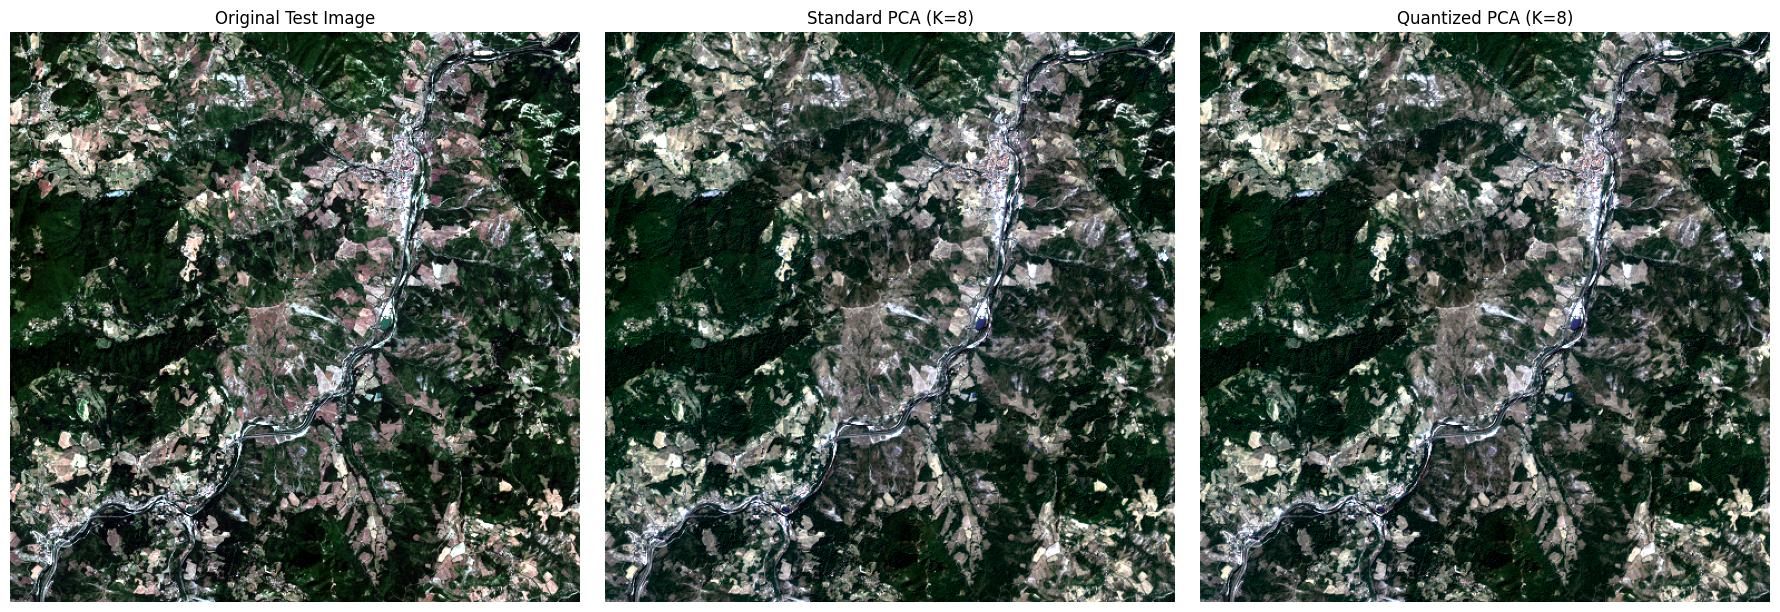


========== COMPRESSION COMPARISON ==========
Original size       : 6656.12 KB

Standard PCA
Compressed size     : 7687.33 KB
Compression ratio   : 0.866
PSNR                : 45.0248 dB
SSIM                : 0.986290

Quantized PCA
Compressed size     : 1881.85 KB
Compression ratio   : 3.537
PSNR                : 44.9331 dB
SSIM                : 0.985946


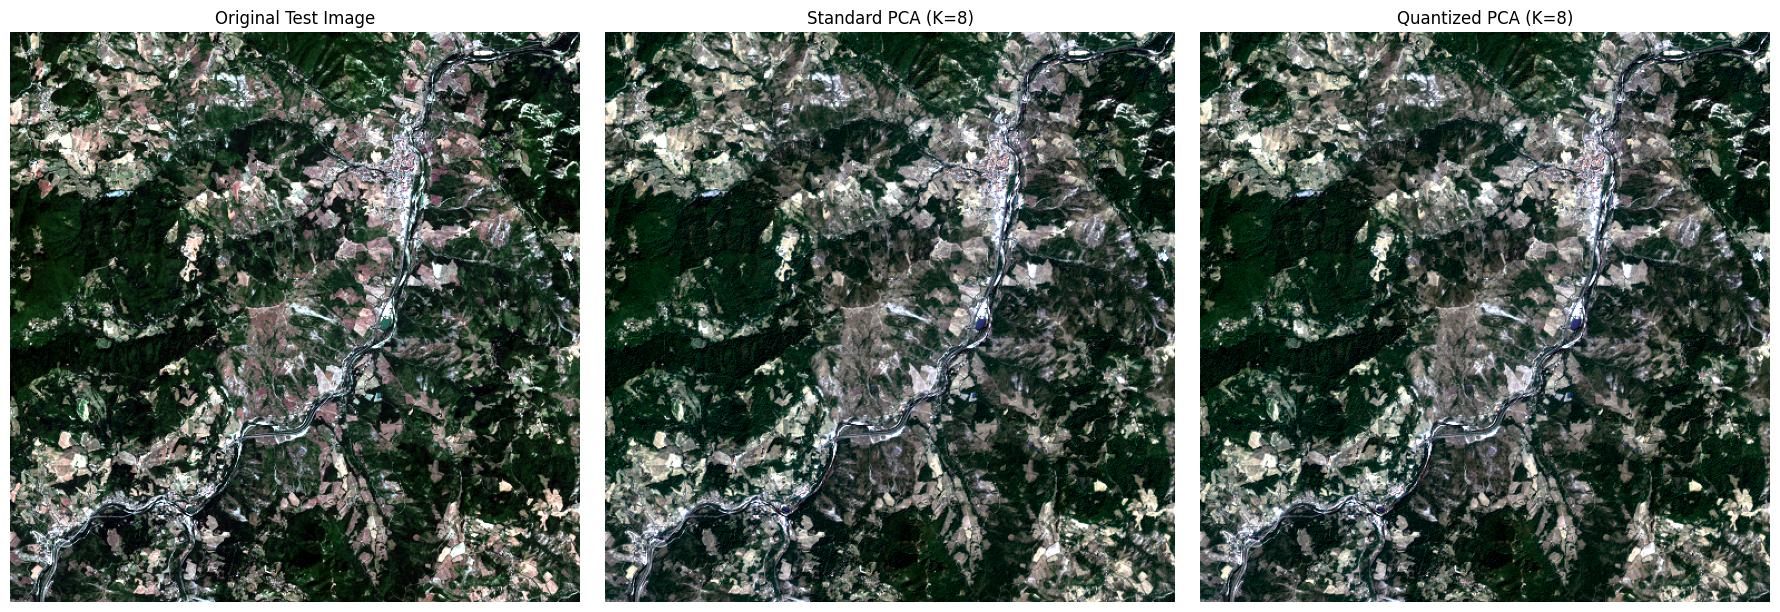


Saved files:
compression_comparison.csv
rgb_compression_comparison.png


In [14]:

import numpy as np
import matplotlib.pyplot as plt
import io
import os
from skimage.metrics import structural_similarity

# --------------------------------------------------
# 1. SELECT PCA COMPONENTS
# --------------------------------------------------

K = 8
selected_components = components[:K]

pixels = original_image.reshape(13, -1).T

# --------------------------------------------------
# 2. STANDARD PCA: ENCODE AND DECODE
# --------------------------------------------------

standard_scores = (
    (pixels - mean) @ selected_components.T
).astype(np.float32)

standard_buffer = io.BytesIO()
np.savez_compressed(standard_buffer, scores=standard_scores)
standard_size = len(standard_buffer.getvalue())

standard_restored = (
    standard_scores @ selected_components + mean
).T.reshape(13, 512, 512)

standard_restored = np.clip(standard_restored, 0, 1)

# --------------------------------------------------
# 3. QUANTIZED PCA: ENCODE AND DECODE
# --------------------------------------------------

score_min = standard_scores.min(axis=0)
score_max = standard_scores.max(axis=0)

score_range = np.maximum(score_max - score_min, 1e-8)

quantized_scores = np.round(
    (standard_scores - score_min) / score_range * 255
).clip(0, 255).astype(np.uint8)

quantized_buffer = io.BytesIO()

np.savez_compressed(
    quantized_buffer,
    scores=quantized_scores,
    score_min=score_min,
    score_max=score_max
)

quantized_size = len(quantized_buffer.getvalue())

restored_scores = (
    quantized_scores.astype(np.float32) / 255
) * score_range + score_min

quantized_restored = (
    restored_scores @ selected_components + mean
).T.reshape(13, 512, 512)

quantized_restored = np.clip(quantized_restored, 0, 1)

# --------------------------------------------------
# 4. CALCULATE PSNR AND SSIM
# --------------------------------------------------

def calculate_quality(original, reconstructed):
    mse = np.mean((original - reconstructed) ** 2)
    psnr = 10 * np.log10(1.0 / max(mse, 1e-12))

    ssim_values = [
        structural_similarity(original[b], reconstructed[b], data_range=1.0)
        for b in range(13)
    ]

    return psnr, np.mean(ssim_values)

standard_psnr, standard_ssim = calculate_quality(
    original_image, standard_restored
)

quantized_psnr, quantized_ssim = calculate_quality(
    original_image, quantized_restored
)

original_size = os.path.getsize(selected_patch)

# --------------------------------------------------
# 5. DISPLAY RGB COMPARISON
# Sentinel-2: B04 = Red, B03 = Green, B02 = Blue
# --------------------------------------------------

def create_rgb(image):
    rgb = np.stack(
        [image[3], image[2], image[1]],
        axis=-1
    )

    # Use original-image percentiles for all three images
    for channel in range(3):
        low, high = np.percentile(
            original_rgb[:, :, channel], [2, 98]
        )
        rgb[:, :, channel] = np.clip(
            (rgb[:, :, channel] - low) / (high - low + 1e-8),
            0, 1
        )

    return rgb

original_rgb = np.stack(
    [original_image[3], original_image[2], original_image[1]],
    axis=-1
)

original_display = create_rgb(original_image)
standard_display = create_rgb(standard_restored)
quantized_display = create_rgb(quantized_restored)

plt.figure(figsize=(18, 6))

images = [
    (original_display, "Original Test Image"),
    (standard_display, "Standard PCA (K=8)"),
    (quantized_display, "Quantized PCA (K=8)")
]

for i, (img, title) in enumerate(images):
    plt.subplot(1, 3, i + 1)
    plt.imshow(img)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 6. PRINT COMPRESSION RESULTS
# --------------------------------------------------

print("\n========== COMPRESSION COMPARISON ==========")

print(f"Original size       : {original_size / 1024:.2f} KB")

print("\nStandard PCA")
print(f"Compressed size     : {standard_size / 1024:.2f} KB")
print(f"Compression ratio   : {original_size / standard_size:.3f}")
print(f"PSNR                : {standard_psnr:.4f} dB")
print(f"SSIM                : {standard_ssim:.6f}")

print("\nQuantized PCA")
print(f"Compressed size     : {quantized_size / 1024:.2f} KB")
print(f"Compression ratio   : {original_size / quantized_size:.3f}")
print(f"PSNR                : {quantized_psnr:.4f} dB")
print(f"SSIM                : {quantized_ssim:.6f}")


# --------------------------------------------------
# 7. SAVE RGB COMPARISON AND RESULTS
# --------------------------------------------------

SAVE_PATH = "/kaggle/working/compression_visualization"
os.makedirs(SAVE_PATH, exist_ok=True)

# Save RGB comparison image
plt.figure(figsize=(18, 6))

images = [
    (original_display, "Original Test Image"),
    (standard_display, "Standard PCA (K=8)"),
    (quantized_display, "Quantized PCA (K=8)")
]

for i, (img, title) in enumerate(images):
    plt.subplot(1, 3, i + 1)
    plt.imshow(img)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()

plt.savefig(
    os.path.join(SAVE_PATH, "rgb_compression_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save numerical results as CSV
results = pd.DataFrame([
    {
        "Method": "Standard PCA",
        "Compressed Size (KB)": standard_size / 1024,
        "Compression Ratio": original_size / standard_size,
        "PSNR (dB)": standard_psnr,
        "SSIM": standard_ssim
    },
    {
        "Method": "Quantized PCA",
        "Compressed Size (KB)": quantized_size / 1024,
        "Compression Ratio": original_size / quantized_size,
        "PSNR (dB)": quantized_psnr,
        "SSIM": quantized_ssim
    }
])

results.to_csv(
    os.path.join(SAVE_PATH, "compression_comparison.csv"),
    index=False
)

print("\nSaved files:")
for file in os.listdir(SAVE_PATH):
    print(file)

In [15]:
import pandas as pd
import plotly.express as px

# Load region-wise results
df = pd.read_csv(
    "/kaggle/working/test_results/test_region_summary.csv"
)

# Prepare data
psnr_data = df.pivot(
    index="region",
    columns="method",
    values="psnr"
)

# Create heatmap
fig = px.imshow(
    psnr_data,
    text_auto=".3f",
    color_continuous_scale="RdYlGn",
    aspect="auto",
    title="Region-wise PSNR Comparison: Standard PCA vs Quantized PCA",
    labels={
        "x": "Compression Method",
        "y": "Satellite Region",
        "color": "PSNR (dB)"
    }
)

fig.update_layout(
    width=850,
    height=550
)

fig.show()

# Save
fig.write_html(
    "/kaggle/working/test_results/heatmap_region_psnr.html"
)